<a href="https://colab.research.google.com/github/Alk207-lab/-Machine-learning-projects-Sem1/blob/main/Ex9_diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 9: Diabetes Prediction Using Bagging Ensemble Technique

**Aim:** Predict whether a person has diabetes using clinical features such as blood pressure, skin thickness and age, and perform comparative analysis among **Bagging Classifier, Random Forest and Decision Tree Classifier**.

**Dataset:** Diabetes dataset supplied through the experiment link.

**Evaluation:** Accuracy, Precision, Recall, F1-score, ROC-AUC, confusion matrices and model comparison graph.

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay)

RANDOM_STATE = 42
print('Libraries imported successfully.')

Libraries imported successfully.


## 1. Load the Dataset
Download the linked diabetes CSV and save it beside this notebook. The loader below accepts common names such as `diabetes.csv` or `diabetes_dataset.csv`.

In [2]:
import glob, os

candidates = ['diabetes.csv', 'diabetes_dataset.csv', 'Diabetes.csv']
path = next((p for p in candidates if os.path.exists(p)), None)
if path is None:
    csvs = [p for p in glob.glob('*.csv') if 'diabet' in p.lower()]
    path = csvs[0] if csvs else None
if path is None:
    raise FileNotFoundError('Place the diabetes CSV in the same folder as this notebook.')

data = pd.read_csv(path)
print('Loaded:', path)
print('Shape:', data.shape)
data.head()

Loaded: diabetes.csv
Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
# Standardize column names when the file uses the usual Pima schema
data.columns = [str(c).strip() for c in data.columns]
print(data.info())
print('\nMissing values per column:')
print(data.isnull().sum())
print('\nClass distribution:')
target_col = 'Outcome' if 'Outcome' in data.columns else data.columns[-1]
print(data[target_col].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None

Missing values per column:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction   

In [4]:
# Separate features and target
target_col = 'Outcome' if 'Outcome' in data.columns else data.columns[-1]
X = data.drop(columns=[target_col]).copy()
y = data[target_col].astype(int).copy()

# In the common Pima dataset, zero is physiologically invalid for these measurements.
zero_as_missing = [c for c in ['Glucose','BloodPressure','SkinThickness','Insulin','BMI'] if c in X.columns]
X[zero_as_missing] = X[zero_as_missing].replace(0, np.nan)

print('Target column:', target_col)
print('Zero-to-missing columns:', zero_as_missing)
print('Features:', list(X.columns))

Target column: Outcome
Zero-to-missing columns: ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
Features: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']


In [5]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print('Training samples:', X_train.shape[0])
print('Testing samples :', X_test.shape[0])

Training samples: 614
Testing samples : 154


## 2. Build Bagging, Random Forest and Decision Tree Models
Median imputation is performed inside each pipeline to prevent information leakage from the test set.

In [6]:
# Compatibility helper for different scikit-learn versions
base_tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
try:
    bagger = BaggingClassifier(estimator=base_tree, n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
except TypeError:
    bagger = BaggingClassifier(base_estimator=base_tree, n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)

models = {
    'Bagging Classifier': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', bagger)
    ]),
    'Random Forest': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))
    ]),
    'Decision Tree': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', DecisionTreeClassifier(random_state=RANDOM_STATE))
    ])
}
print('Models:', list(models.keys()))

Models: ['Bagging Classifier', 'Random Forest', 'Decision Tree']


## 3. Comparative Analysis

In [7]:
results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    predictions[name] = y_pred

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).sort_values('F1-Score', ascending=False).reset_index(drop=True)
results_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.7403,0.6522,0.5556,0.6000,0.8168
1,Bagging Classifier,0.7273,0.6364,0.5185,0.5714,0.8102
2,Decision Tree,0.6818,0.5532,0.4815,0.5149,0.6357


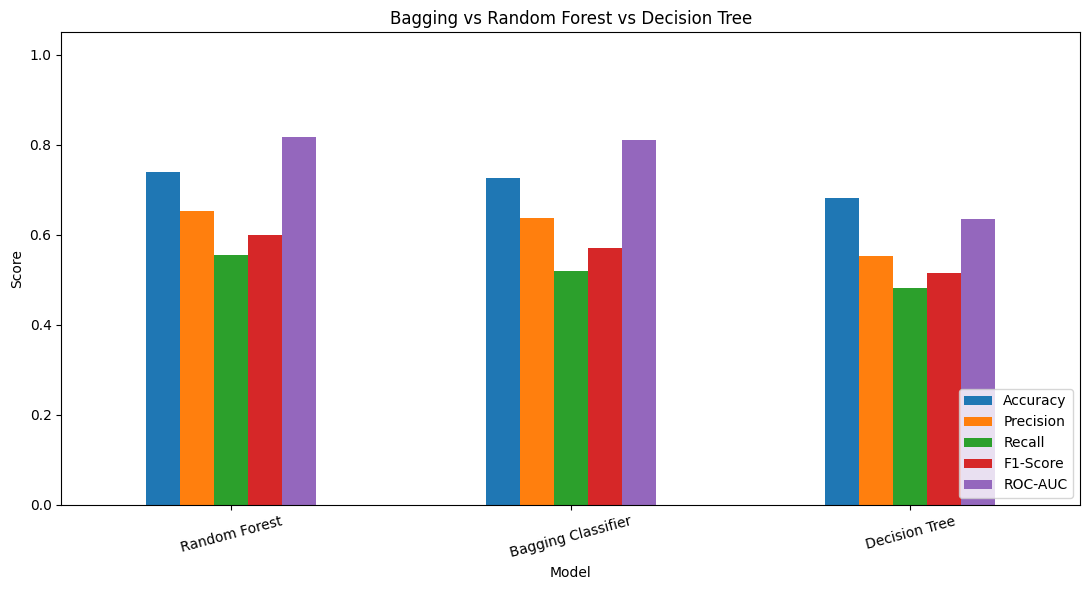

In [8]:
# Comparison graph
plot_df = results_df.set_index('Model')[['Accuracy','Precision','Recall','F1-Score','ROC-AUC']]
plot_df.plot(kind='bar', figsize=(11,6))
plt.ylim(0,1.05)
plt.ylabel('Score')
plt.title('Bagging vs Random Forest vs Decision Tree')
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

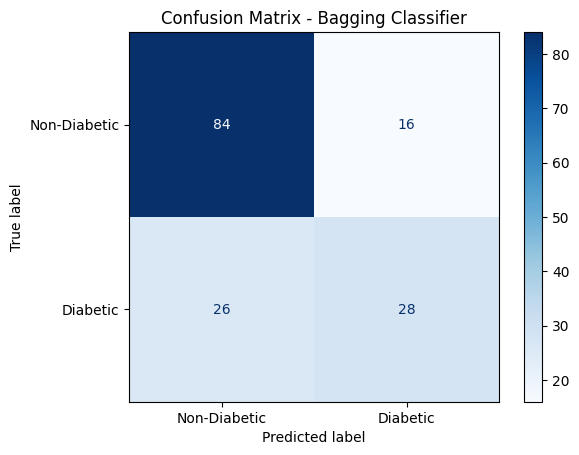

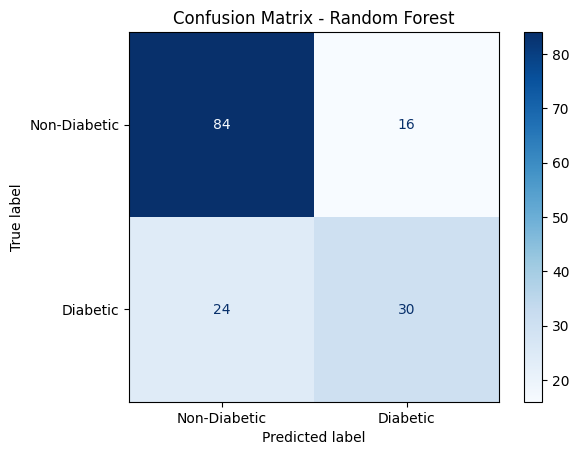

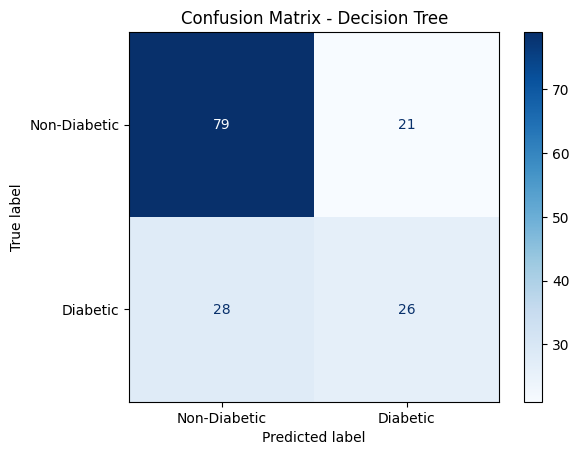

In [9]:
# Confusion matrices
for name, y_pred in predictions.items():
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=['Non-Diabetic','Diabetic'], cmap='Blues'
    )
    plt.title(f'Confusion Matrix - {name}')
    plt.show()

In [10]:
# Classification reports
for name, y_pred in predictions.items():
    print('\n' + '='*60)
    print(name)
    print('='*60)
    print(classification_report(y_test, y_pred, target_names=['Non-Diabetic','Diabetic']))


Bagging Classifier
              precision    recall  f1-score   support

Non-Diabetic       0.76      0.84      0.80       100
    Diabetic       0.64      0.52      0.57        54

    accuracy                           0.73       154
   macro avg       0.70      0.68      0.69       154
weighted avg       0.72      0.73      0.72       154


Random Forest
              precision    recall  f1-score   support

Non-Diabetic       0.78      0.84      0.81       100
    Diabetic       0.65      0.56      0.60        54

    accuracy                           0.74       154
   macro avg       0.71      0.70      0.70       154
weighted avg       0.73      0.74      0.73       154


Decision Tree
              precision    recall  f1-score   support

Non-Diabetic       0.74      0.79      0.76       100
    Diabetic       0.55      0.48      0.51        54

    accuracy                           0.68       154
   macro avg       0.65      0.64      0.64       154
weighted avg       0.67 

Glucose                     0.268040
BMI                         0.158169
DiabetesPedigreeFunction    0.124418
Age                         0.120007
Insulin                     0.091532
BloodPressure               0.085172
Pregnancies                 0.079317
SkinThickness               0.073344
dtype: float64


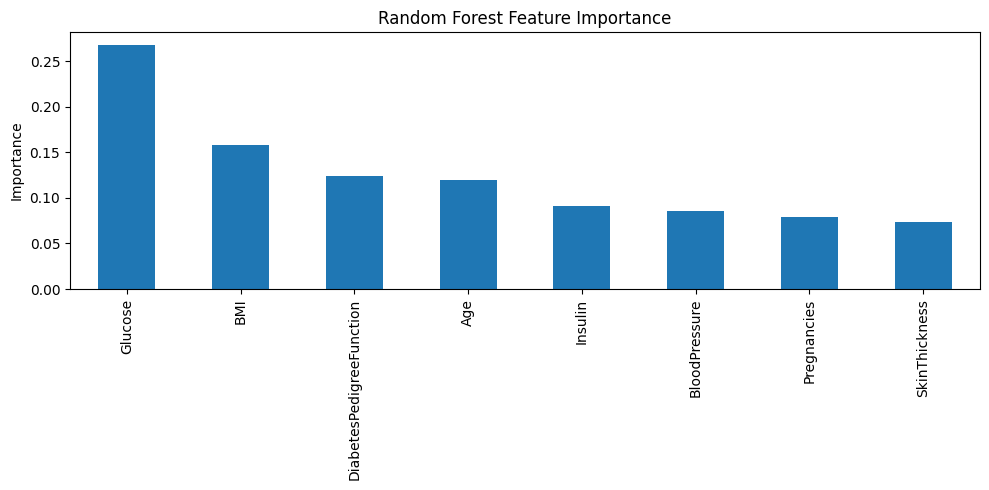

In [11]:
# Feature importance comparison for tree-based models
# All three methods are tree-based; display Random Forest importance as a stable summary.
rf_pipe = models['Random Forest']
importances = rf_pipe.named_steps['model'].feature_importances_
imp = pd.Series(importances, index=X.columns).sort_values(ascending=False)
print(imp)
imp.plot(kind='bar', figsize=(10,5))
plt.ylabel('Importance')
plt.title('Random Forest Feature Importance')
plt.tight_layout()
plt.show()

In [12]:
best_model = results_df.iloc[0]['Model']
print('Best model based on F1-Score:', best_model)
print('\nFinal comparative table:')
print(results_df.round(4).to_string(index=False))

Best model based on F1-Score: Random Forest

Final comparative table:
             Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
     Random Forest    0.7403     0.6522  0.5556    0.6000   0.8168
Bagging Classifier    0.7273     0.6364  0.5185    0.5714   0.8102
     Decision Tree    0.6818     0.5532  0.4815    0.5149   0.6357


## 4. Result and Conclusion
- **Decision Tree** creates one tree and can overfit the training data.
- **Bagging** trains many decision trees on bootstrap samples and combines their predictions, generally reducing variance.
- **Random Forest** extends bagging by also selecting random subsets of features, which can increase diversity among trees.

The final comparison table objectively identifies the strongest model for the given train-test split. In diabetes screening, Recall is important because it measures how many actual diabetic cases are detected, while F1-score balances Precision and Recall.

**Result:** Run all cells and record the top-ranked model from the final comparative table.